# Mini Project 11 — Running Project Keyword Spotting Embedded

**Anggota Kelompok:**
1. Christama Ezra Yudianto (245150307111009)
2. Abdillah Fatah Suryanto (245150300111008)
3. Ivang Arfandia (245150307111003)
4. Jahzeel Erason Nicodemus (245150300111002)

Notebook ini dibangkitkan dari `mini_project_11.py` (bagian wajib) dan `features/mp11_extension_classifier_analysis.py` (FITUR TAMBAHAN) lalu dieksekusi dari root folder mini project.

# Mini Project 11 — Membandingkan dan Membekukan Baseline Machine Learning
Representasi final MP10 dipakai tanpa feature selection ulang. Enam keluarga classifier
(KNN, logistic regression, linear SVM, decision tree, random forest, MLP) di-tuning dengan
GroupKFold TRAIN, keluarga final dipilih dengan VALIDATION, test set tetap terkunci.
Status -> `ready_for_mp12`.

In [1]:
# Anggota Kelompok :
# 1. Christama Ezra Yudianto    (245150307111009)
# 2. Abdillah Fatah Suryanto    (245150300111008)
# 3. Ivang Arfandia             (245150307111003)
# 4. Jahzeel Erason Nicodemus   (245150300111002)
from pathlib import Path
import json, pickle, warnings
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
import joblib

warnings.filterwarnings('ignore')
ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
SEED = 2026
VAL_TOL = 0.03

## Helper: CV GroupKFold & resource proxy

In [2]:
def save_json(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2), encoding='utf-8')


def as_py(v):
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.floating,)): return float(v)
    if isinstance(v, np.ndarray): return v.tolist()
    if isinstance(v, tuple): return list(v)
    return v


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro', zero_division=0)


def cv_score(estimator, X, y, groups):
    unique_groups = np.unique(groups)
    n_splits = min(4, len(unique_groups))
    if n_splits < 2:
        raise RuntimeError('Training set membutuhkan minimal dua acquisition group.')
    cv = GroupKFold(n_splits=n_splits)
    scores = []
    for tr, va in cv.split(X, y, groups):
        model = clone(estimator)
        model.fit(X[tr], y[tr])
        pred = model.predict(X[va])
        scores.append(macro_f1(y[va], pred))
    return float(np.mean(scores)), float(np.std(scores)), [float(s) for s in scores]


def model_stats(name, model, X_train):
    # Perkiraan operasi primitif per sampel, dipakai hanya sebagai pembanding relatif.
    d = X_train.shape[1]
    if name == 'knn':
        ops = int(X_train.shape[0] * d * 3)
        params = int(X_train.size + X_train.shape[0])
    elif name in ('logreg', 'linear_svm'):
        coef = np.asarray(model.coef_)
        ops = int(coef.size * 2)
        params = int(coef.size + np.asarray(model.intercept_).size)
    elif name == 'tree':
        ops = int(model.get_depth())
        params = int(model.tree_.node_count)
    elif name == 'rf':
        ops = int(sum(est.get_depth() for est in model.estimators_))
        params = int(sum(est.tree_.node_count for est in model.estimators_))
    elif name == 'mlp':
        params = int(sum(w.size for w in model.coefs_) + sum(b.size for b in model.intercepts_))
        ops = int(2 * sum(w.size for w in model.coefs_))
    else:
        ops = params = 0
    size = len(pickle.dumps(model, protocol=pickle.HIGHEST_PROTOCOL))
    return {'estimated_ops_per_sample': ops, 'parameter_count_proxy': params, 'serialized_bytes': int(size)}

## 1. Validasi handoff MP10 (test tetap terkunci)

In [3]:
status_path = ROOT / 'project_status.json'
if not status_path.exists():
    raise FileNotFoundError('project_status.json tidak ditemukan. Jalankan Mini Project sebelumnya.')
status = json.loads(status_path.read_text(encoding='utf-8'))
if status.get('status') not in ('ready_for_mp11', 'ready_for_mp12'):
    raise RuntimeError(f"Status harus ready_for_mp11, ditemukan {status.get('status')!r}")

src = ROOT / 'features/dataset/mp10_features_final.npz'
if not src.exists():
    raise FileNotFoundError(src)
D = np.load(src, allow_pickle=True)
X = D['X'].astype(np.float64)
y = D['y'].astype(str)
groups = D['groups'].astype(str)
train_mask = D['train_mask'].astype(bool)
val_mask = D['val_mask'].astype(bool)
test_mask = D['test_mask'].astype(bool)
sample_ids = D['sample_ids'].astype(str)
if not np.isfinite(X).all():
    raise RuntimeError('Dataset MP10 mengandung NaN/Inf.')
if train_mask.sum() < 8 or val_mask.sum() < 4 or test_mask.sum() < 4:
    raise RuntimeError('Split MP9/MP10 tidak sesuai running project.')

Xtr, ytr, gtr = X[train_mask], y[train_mask], groups[train_mask]
Xv, yv = X[val_mask], y[val_mask]
classes = np.unique(y)
print('Input dim =', X.shape[1], '| train/val/test(terkunci) =', len(ytr), len(yv), int(test_mask.sum()))

Input dim = 8 | train/val/test(terkunci) = 16 4 4


## 2. Grid kecil per keluarga model

In [4]:
families = {
    'knn': [{'n_neighbors': 1, 'weights': 'uniform'},
            {'n_neighbors': 3, 'weights': 'uniform'},
            {'n_neighbors': 3, 'weights': 'distance'}],
    'logreg': [{'C': 0.1}, {'C': 1.0}, {'C': 10.0}],
    'linear_svm': [{'C': 0.1}, {'C': 1.0}, {'C': 10.0}],
    'tree': [{'max_depth': 2}, {'max_depth': 3}, {'max_depth': 4}],
    'rf': [{'n_estimators': 30, 'max_depth': 3}, {'n_estimators': 50, 'max_depth': 4}],
    'mlp': [{'hidden_layer_sizes': (8,), 'alpha': 1e-3}, {'hidden_layer_sizes': (16,), 'alpha': 1e-3}],
}


def build(name, p):
    if name == 'knn':
        return KNeighborsClassifier(**p)
    if name == 'logreg':
        return LogisticRegression(max_iter=2000, solver='lbfgs', random_state=SEED, **p)
    if name == 'linear_svm':
        return LinearSVC(dual='auto', random_state=SEED, **p)
    if name == 'tree':
        return DecisionTreeClassifier(random_state=SEED, min_samples_leaf=1, **p)
    if name == 'rf':
        return RandomForestClassifier(random_state=SEED, n_jobs=1, **p)
    if name == 'mlp':
        return MLPClassifier(max_iter=2500, activation='relu', solver='lbfgs', random_state=SEED, **p)
    raise KeyError(name)

## 3. Tuning hyperparameter per family dengan training GroupKFold saja

In [5]:
family_results = {}
models = {}
for family, grid in families.items():
    trials = []
    for hp in grid:
        est = build(family, hp)
        mean_f1, std_f1, fold_scores = cv_score(est, Xtr, ytr, gtr)
        trials.append({'params': {k: as_py(v) for k, v in hp.items()},
                       'cv_macro_f1_mean': mean_f1,
                       'cv_macro_f1_std': std_f1,
                       'fold_macro_f1': fold_scores})
    best = sorted(trials, key=lambda r: (-r['cv_macro_f1_mean'], r['cv_macro_f1_std']))[0]
    model = build(family, best['params'])
    # tuple MLP disimpan JSON sebagai list; konversi kembali saat perlu.
    if family == 'mlp' and isinstance(best['params'].get('hidden_layer_sizes'), list):
        hp2 = dict(best['params']); hp2['hidden_layer_sizes'] = tuple(hp2['hidden_layer_sizes'])
        model = build(family, hp2)
    model.fit(Xtr, ytr)
    pred_val = model.predict(Xv)
    val_f1 = macro_f1(yv, pred_val)
    val_acc = accuracy_score(yv, pred_val)
    stats = model_stats(family, model, Xtr)
    family_results[family] = {
        'best_params': best['params'],
        'cv_macro_f1_mean': best['cv_macro_f1_mean'],
        'cv_macro_f1_std': best['cv_macro_f1_std'],
        'validation_macro_f1': float(val_f1),
        'validation_accuracy': float(val_acc),
        'resource_proxy': stats,
        'all_trials': trials,
        'validation_predictions': pred_val.tolist(),
    }
    models[family] = model
    print(f"  {family:10s} best={best['params']}  CV F1={best['cv_macro_f1_mean']:.3f}  val F1={val_f1:.3f}  "
          f"ops={stats['estimated_ops_per_sample']}  bytes={stats['serialized_bytes']}")

  knn        best={'n_neighbors': 1, 'weights': 'uniform'}  CV F1=1.000  val F1=1.000  ops=384  bytes=2573
  logreg     best={'C': 0.1}  CV F1=1.000  val F1=1.000  ops=64  bytes=1074
  linear_svm best={'C': 0.1}  CV F1=1.000  val F1=1.000  ops=64  bytes=909
  tree       best={'max_depth': 2}  CV F1=1.000  val F1=1.000  ops=2  bytes=1857
  rf         best={'n_estimators': 30, 'max_depth': 3}  CV F1=0.833  val F1=1.000  ops=80  bytes=30801
  mlp        best={'hidden_layer_sizes': [8], 'alpha': 0.001}  CV F1=1.000  val F1=1.000  ops=192  bytes=8547


## 4. Pilih keluarga final dengan validation, biaya sebagai tie-break

In [6]:
best_val = max(r['validation_macro_f1'] for r in family_results.values())
shortlist = [n for n, r in family_results.items() if r['validation_macro_f1'] >= best_val - VAL_TOL]
# Bias kecil ke model yang CV-nya lebih stabil, lalu operasi dan ukuran lebih kecil.
chosen = sorted(shortlist, key=lambda n: (
    -family_results[n]['validation_macro_f1'],
    -family_results[n]['cv_macro_f1_mean'],
    family_results[n]['resource_proxy']['estimated_ops_per_sample'],
    family_results[n]['resource_proxy']['serialized_bytes'],
))[0]
model = models[chosen]
val_pred = model.predict(Xv)
cm = confusion_matrix(yv, val_pred, labels=classes)
print('Shortlist (val F1 >= best-0.03):', shortlist, '| chosen =', chosen)

Shortlist (val F1 >= best-0.03): ['knn', 'logreg', 'linear_svm', 'tree', 'rf', 'mlp'] | chosen = tree


## 5. Simpan model & artefak (test sengaja tidak diprediksi)

In [7]:
model_dir = ROOT / 'models'; model_dir.mkdir(parents=True, exist_ok=True)
result_dir = ROOT / 'results/metrics'; result_dir.mkdir(parents=True, exist_ok=True)
fig_dir = ROOT / 'results/figures'; fig_dir.mkdir(parents=True, exist_ok=True)
config_dir = ROOT / 'config'; config_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / 'mp11_classical_baseline.joblib'
joblib.dump(model, model_path)

# Parameter numerik ringkas untuk porting/audit.
param_path = model_dir / 'mp11_model_parameters.npz'
param_payload = {'classes': np.array(classes, dtype=object), 'model_family': np.array([chosen], dtype=object)}
if chosen in ('logreg', 'linear_svm'):
    param_payload['coef'] = np.asarray(model.coef_, dtype=np.float32)
    param_payload['intercept'] = np.asarray(model.intercept_, dtype=np.float32)
elif chosen == 'tree':
    param_payload.update({
        'children_left': model.tree_.children_left.astype(np.int32),
        'children_right': model.tree_.children_right.astype(np.int32),
        'feature': model.tree_.feature.astype(np.int32),
        'threshold': model.tree_.threshold.astype(np.float32),
        'value': model.tree_.value.astype(np.float32),
    })
elif chosen == 'knn':
    param_payload['train_X'] = model._fit_X.astype(np.float32)
    param_payload['train_y_encoded'] = np.asarray(model._y, dtype=np.int32)
elif chosen == 'mlp':
    for i, w in enumerate(model.coefs_): param_payload[f'W{i}'] = np.asarray(w, dtype=np.float32)
    for i, b in enumerate(model.intercepts_): param_payload[f'b{i}'] = np.asarray(b, dtype=np.float32)
elif chosen == 'rf':
    param_payload['n_estimators'] = np.array([len(model.estimators_)], dtype=np.int32)
np.savez_compressed(param_path, **param_payload)

if chosen == 'tree':
    (model_dir/'mp11_tree_rules.txt').write_text(export_text(model), encoding='utf-8')

config = {
    'source_dataset': 'features/dataset/mp10_features_final.npz',
    'feature_representation_frozen_in_mp10': True,
    'hyperparameter_fit_scope': 'training_only_groupkfold',
    'family_selection_scope': 'validation_only_after_family_tuning',
    'test_used_for_tuning': False,
    'test_used_for_family_selection': False,
    'test_predictions_generated': False,
    'seed': SEED,
    'validation_f1_tolerance': VAL_TOL,
    'chosen_family': chosen,
    'chosen_params': family_results[chosen]['best_params'],
    'classes': classes.tolist(),
    'input_dim': int(X.shape[1]),
    'model_file': 'models/mp11_classical_baseline.joblib',
    'parameter_file': 'models/mp11_model_parameters.npz',
}
save_json(config_dir/'classifier_config.json', config)

report = {
    'n_samples_total': int(len(y)),
    'n_train': int(train_mask.sum()),
    'n_validation': int(val_mask.sum()),
    'n_test_reserved_untouched': int(test_mask.sum()),
    'input_dim': int(X.shape[1]),
    'classes': classes.tolist(),
    'family_results': family_results,
    'best_validation_macro_f1': float(best_val),
    'shortlist_within_tolerance': shortlist,
    'chosen_family': chosen,
    'chosen_validation_macro_f1': float(family_results[chosen]['validation_macro_f1']),
    'chosen_validation_accuracy': float(family_results[chosen]['validation_accuracy']),
    'validation_confusion_matrix': cm.tolist(),
    'test_used': False,
}
save_json(result_dir/'mp11_classifier_metrics.json', report)

## 6. Gambar: perbandingan classifier, trade-off sumber daya, confusion matrix validation

In [8]:
names = list(family_results.keys())
cv_vals = [family_results[n]['cv_macro_f1_mean'] for n in names]
val_vals = [family_results[n]['validation_macro_f1'] for n in names]
xpos = np.arange(len(names))
plt.figure(figsize=(8.4, 4.8))
plt.bar(xpos-0.18, cv_vals, width=0.36, label='Training GroupKFold')
plt.bar(xpos+0.18, val_vals, width=0.36, label='Validation block')
plt.xticks(xpos, names, rotation=20)
plt.ylabel('Macro-F1'); plt.ylim(0, 1.05); plt.title('MP11 - Perbandingan classifier')
plt.legend(); plt.grid(axis='y', alpha=.2); plt.tight_layout()
plt.savefig(fig_dir/'mp11_classifier_comparison.png', dpi=170); plt.close()

sizes = [family_results[n]['resource_proxy']['serialized_bytes'] for n in names]
ops = [family_results[n]['resource_proxy']['estimated_ops_per_sample'] for n in names]
plt.figure(figsize=(7.4, 5.0))
plt.scatter(ops, sizes, s=80)
for n, a, b in zip(names, ops, sizes): plt.annotate(n, (a, b), xytext=(4, 4), textcoords='offset points', fontsize=8)
plt.xlabel('Estimated primitive operations / sample (proxy)')
plt.ylabel('Serialized model bytes (proxy)')
plt.title('MP11 - Trade-off sumber daya classifier')
plt.grid(alpha=.2); plt.tight_layout()
plt.savefig(fig_dir/'mp11_resource_tradeoff.png', dpi=170); plt.close()

plt.figure(figsize=(5.4, 4.7))
plt.imshow(cm, cmap='Blues')
plt.colorbar(label='Jumlah sampel')
plt.xticks(range(len(classes)), classes, rotation=30); plt.yticks(range(len(classes)), classes)
plt.xlabel('Prediksi'); plt.ylabel('Label aktual'); plt.title(f'Validation confusion matrix - {chosen}')
for i in range(len(classes)):
    for j in range(len(classes)):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center')
plt.tight_layout(); plt.savefig(fig_dir/'mp11_validation_confusion_matrix.png', dpi=170); plt.close()

## 7. Update status untuk MP12

In [9]:
status['status'] = 'ready_for_mp12'
status['last_completed_mini_project'] = 11
status['mp11'] = {
    'chosen_family': chosen,
    'classifier_config': 'config/classifier_config.json',
    'model_file': 'models/mp11_classical_baseline.joblib',
    'parameter_file': 'models/mp11_model_parameters.npz',
    'metrics': 'results/metrics/mp11_classifier_metrics.json',
    'test_used': False,
}
save_json(status_path, status)

print('Mini Project 11 selesai.')
print('Chosen family:', chosen, family_results[chosen]['best_params'])
print('Validation macro-F1:', f"{family_results[chosen]['validation_macro_f1']:.3f}")
print('Test used:', False)
print('Status:', status['status'])

Mini Project 11 selesai.
Chosen family: tree {'max_depth': 2}
Validation macro-F1: 1.000
Test used: False
Status: ready_for_mp12


---
# FITUR TAMBAHAN (di luar tugas wajib)
Sumber: `features/mp11_extension_classifier_analysis.py`

## FITUR TAMBAHAN MP11 — Keluarga Model Tambahan, Robustness, Export C & Verifikasi gcc
Modul mandiri setelah `mini_project_11.py`. Model beku MP11 **tidak diubah**, test **tidak dibuka**.

Fitur tambahan (materi Bab 11: kernel SVM, hardware-aware, parameter tersimpan):
1. **Keluarga tambahan**: SVM RBF, Gaussian Naive Bayes, LDA classifier (protokol identik).
2. **Overfitting gap** (train-fit F1 vs GroupKFold F1) & **robustness terhadap derau fitur**
   (σ = 0.25/0.5/1.0 pada fitur terstandar, GroupKFold TRAIN) — semua keluarga seri di F1=1.0,
   sehingga robustness memberi informasi tambahan tentang margin keputusan.
3. **Arsip semua kandidat beku** (`models/mp11_family_models/*.joblib`, fit TRAIN saja) + SHA-256,
   agar jalur SVM INT8 versi buku tetap dapat dibangun di MP15 tanpa retraining.
4. **Export model terpilih ke C** (`firmware/mp11_classifier_float.h`, tree → if/else, linear → dot product)
   lalu **dikompilasi dengan gcc** dan diverifikasi identik dengan scikit-learn pada TRAIN+VALIDATION.
5. **Latency inferensi host** per keluarga (proxy).

Anggota Kelompok : Christama Ezra Yudianto (245150307111009), Abdillah Fatah Suryanto (245150300111008),
Ivang Arfandia (245150307111003), Jahzeel Erason Nicodemus (245150300111002)

In [10]:
from pathlib import Path
import json, hashlib, shutil, subprocess, time, warnings
import numpy as np
import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import f1_score
from sklearn.model_selection import GroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

warnings.filterwarnings('ignore')
ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd()
SEED = 2026
status = json.loads((ROOT/'project_status.json').read_text(encoding='utf-8'))
assert status['status'] in ('ready_for_mp12',), 'Jalankan mini_project_11.py terlebih dahulu'
cfg = json.loads((ROOT/'config/classifier_config.json').read_text(encoding='utf-8'))
rep = json.loads((ROOT/'results/metrics/mp11_classifier_metrics.json').read_text(encoding='utf-8'))
D = np.load(ROOT/'features/dataset/mp10_features_final.npz', allow_pickle=True)
X = D['X'].astype(np.float64); y = D['y'].astype(str); g = D['groups'].astype(str)
tr = D['train_mask'].astype(bool); va = D['val_mask'].astype(bool)
Xtr, ytr, gtr, Xv, yv = X[tr], y[tr], g[tr], X[va], y[va]
classes = list(cfg['classes'])
OUT_MET = ROOT/'results/metrics'; OUT_FIG = ROOT/'results/figures'; FW = ROOT/'firmware'
FAM_DIR = ROOT/'models/mp11_family_models'
for d in (FW, FAM_DIR):
    d.mkdir(parents=True, exist_ok=True)
cv = GroupKFold(n_splits=min(4, len(np.unique(gtr))))

# rebuild model tuned MP11 dari best_params (fit TRAIN saja — sama persis dengan MP11)
exec_ns = {}
src = (ROOT/'mini_project_11.py').read_text(encoding='utf-8')
build_src = src[src.index('def build(name, p):'):src.index('# %% [markdown]\n# ## 3.')]
exec('from sklearn.neighbors import KNeighborsClassifier\nfrom sklearn.linear_model import LogisticRegression\n'
     'from sklearn.svm import LinearSVC\nfrom sklearn.tree import DecisionTreeClassifier\n'
     'from sklearn.ensemble import RandomForestClassifier\nfrom sklearn.neural_network import MLPClassifier\n'
     f'SEED={SEED}\n' + build_src, exec_ns)
build = exec_ns['build']


def fam_model(name):
    p = dict(rep['family_results'][name]['best_params'])
    if 'hidden_layer_sizes' in p:
        p['hidden_layer_sizes'] = tuple(p['hidden_layer_sizes'])
    return build(name, p)


def cv_f1(est, Xa, noise=0.0, reps=1):
    rng = np.random.default_rng(SEED)
    s = []
    for a, b in cv.split(Xa, ytr, gtr):
        m = clone(est).fit(Xa[a], ytr[a])
        for _ in range(reps):
            Xb = Xa[b] + (rng.normal(0, noise, Xa[b].shape) if noise else 0)
            s.append(f1_score(ytr[b], m.predict(Xb), average='macro'))
    return float(np.mean(s))

### 1. Keluarga tambahan: SVM RBF, Gaussian NB, LDA (grid kecil, protokol identik MP11)

In [11]:
extra = {}
grids = {'svm_rbf': [dict(C=c, gamma='scale') for c in (0.3, 1.0, 3.0)],
         'gaussian_nb': [dict(var_smoothing=v) for v in (1e-9, 1e-3)],
         'lda': [dict(solver='svd')]}
mk = {'svm_rbf': lambda p: SVC(kernel='rbf', random_state=SEED, **p), 'gaussian_nb': lambda p: GaussianNB(**p),
      'lda': lambda p: LinearDiscriminantAnalysis(**p)}
for fam, grid in grids.items():
    trials = [(cv_f1(mk[fam](p), Xtr), p) for p in grid]
    best_cv, best_p = max(trials, key=lambda t: t[0])
    m = mk[fam](best_p).fit(Xtr, ytr)
    sv = int(m.support_vectors_.shape[0]) if fam == 'svm_rbf' else None
    extra[fam] = {'best_params': best_p, 'cv_macro_f1': best_cv,
                  'validation_macro_f1': float(f1_score(yv, m.predict(Xv), average='macro')),
                  'support_vectors': sv,
                  'ops_proxy': (sv*Xtr.shape[1]*3 if sv else (len(classes)*Xtr.shape[1]*4 if fam == 'gaussian_nb' else len(classes)*Xtr.shape[1]*2))}
    print(f"  {fam:12s} {best_p}  CV F1={best_cv:.3f}  val F1={extra[fam]['validation_macro_f1']:.3f}  ops~{extra[fam]['ops_proxy']}")

  svm_rbf      {'C': 0.3, 'gamma': 'scale'}  CV F1=1.000  val F1=1.000  ops~384
  gaussian_nb  {'var_smoothing': 0.001}  CV F1=0.917  val F1=1.000  ops~128
  lda          {'solver': 'svd'}  CV F1=0.490  val F1=1.000  ops~64


### 2. Overfitting gap & robustness terhadap derau fitur (GroupKFold TRAIN)

In [12]:
fams = list(rep['family_results'].keys())
robust = {}
for fam in fams:
    est = fam_model(fam)
    train_fit = f1_score(ytr, clone(est).fit(Xtr, ytr).predict(Xtr), average='macro')
    robust[fam] = {'train_fit_f1': float(train_fit), 'cv_f1': rep['family_results'][fam]['cv_macro_f1_mean'],
                   'overfit_gap': float(train_fit - rep['family_results'][fam]['cv_macro_f1_mean']),
                   'cv_f1_feature_noise': {str(s): cv_f1(est, Xtr, noise=s, reps=20) for s in (0.25, 0.5, 1.0)}}
for fam in extra:
    est = mk[fam](extra[fam]['best_params'])
    robust[fam] = {'train_fit_f1': float(f1_score(ytr, clone(est).fit(Xtr, ytr).predict(Xtr), average='macro')),
                   'cv_f1': extra[fam]['cv_macro_f1'], 'overfit_gap': None,
                   'cv_f1_feature_noise': {str(s): cv_f1(est, Xtr, noise=s, reps=20) for s in (0.25, 0.5, 1.0)}}
    robust[fam]['overfit_gap'] = robust[fam]['train_fit_f1'] - robust[fam]['cv_f1']
for fam, r in robust.items():
    print(f"  {fam:12s} gap={r['overfit_gap']:+.3f}  noise sigma=0.25/0.5/1.0 -> " +
          ' / '.join(f"{v:.3f}" for v in r['cv_f1_feature_noise'].values()))

  knn          gap=+0.000  noise sigma=0.25/0.5/1.0 -> 0.983 / 0.926 / 0.770
  logreg       gap=+0.000  noise sigma=0.25/0.5/1.0 -> 0.958 / 0.892 / 0.755
  linear_svm   gap=+0.000  noise sigma=0.25/0.5/1.0 -> 0.947 / 0.831 / 0.692
  tree         gap=+0.000  noise sigma=0.25/0.5/1.0 -> 0.870 / 0.754 / 0.571
  rf           gap=+0.167  noise sigma=0.25/0.5/1.0 -> 0.802 / 0.774 / 0.661
  mlp          gap=+0.000  noise sigma=0.25/0.5/1.0 -> 0.988 / 0.933 / 0.788
  svm_rbf      gap=+0.000  noise sigma=0.25/0.5/1.0 -> 0.967 / 0.884 / 0.713
  gaussian_nb  gap=+0.083  noise sigma=0.25/0.5/1.0 -> 0.891 / 0.817 / 0.556
  lda          gap=+0.510  noise sigma=0.25/0.5/1.0 -> 0.277 / 0.229 / 0.185


### 3. Arsip semua kandidat beku (fit TRAIN saja) + SHA-256

In [13]:
archive = {}
for fam in fams:
    m = fam_model(fam).fit(Xtr, ytr)
    pred_same = np.array_equal(m.predict(Xv), np.asarray(rep['family_results'][fam]['validation_predictions']))
    p = FAM_DIR/f'mp11_{fam}.joblib'
    joblib.dump(m, p)
    archive[fam] = {'file': p.relative_to(ROOT).as_posix(), 'sha256': hashlib.sha256(p.read_bytes()).hexdigest(),
                    'reproduces_mp11_validation_predictions': bool(pred_same), 'fit_scope': 'training_only',
                    'test_used': False}
print('Arsip kandidat:', {k: v['reproduces_mp11_validation_predictions'] for k, v in archive.items()})

Arsip kandidat: {'knn': True, 'logreg': True, 'linear_svm': True, 'tree': True, 'rf': True, 'mlp': True}


### 4. Export model terpilih ke C + kompilasi gcc + verifikasi identik (TRAIN+VALIDATION)

In [14]:
chosen = cfg['chosen_family']
model = joblib.load(ROOT/cfg['model_file'])
d = X.shape[1]
lines = ['#pragma once', '/* Auto-generated by Mini Project 11 - FITUR TAMBAHAN: classifier float32 C */',
         f'#define MP11_INPUT_DIM {d}', f'#define MP11_N_CLASSES {len(classes)}',
         '/* class order: ' + ', '.join(f'{i}={c}' for i, c in enumerate(classes)) + ' */']
if chosen == 'tree':
    t = model.tree_
    def emit(node, ind):
        if t.children_left[node] == -1:
            cls = int(np.argmax(t.value[node][0]))
            return [f'{ind}return {cls}; /* {model.classes_[cls]} */']
        out = [f'{ind}if (x[{t.feature[node]}] <= {t.threshold[node]:.9g}f) {{']
        out += emit(t.children_left[node], ind + '    ')
        out += [f'{ind}}} else {{'] + emit(t.children_right[node], ind + '    ') + [f'{ind}}}']
        return out
    lines += ['static inline int mp11_predict(const float *x) {'] + emit(0, '    ') + ['}']
elif chosen in ('logreg', 'linear_svm'):
    W = np.asarray(model.coef_, np.float32); b = np.asarray(model.intercept_, np.float32)
    lines += [f'static const float MP11_W[{W.size}] = {{ ' + ', '.join(f'{v:.9g}f' for v in W.ravel()) + ' };',
              f'static const float MP11_B[{b.size}] = {{ ' + ', '.join(f'{v:.9g}f' for v in b) + ' };',
              'static inline int mp11_predict(const float *x) {',
              '    int best = 0; float bs = -1e30f;',
              '    for (int k = 0; k < MP11_N_CLASSES; ++k) { float s = MP11_B[k];',
              '        for (int j = 0; j < MP11_INPUT_DIM; ++j) s += MP11_W[k*MP11_INPUT_DIM+j]*x[j];',
              '        if (s > bs) { bs = s; best = k; } }', '    return best;', '}']
else:
    lines += ['/* Export C otomatis hanya untuk tree/linear; family lain memakai joblib reference. */']
(FW/'mp11_classifier_float.h').write_text('\n'.join(lines) + '\n', encoding='utf-8')

c_check = {'compiled': False}
gcc = shutil.which('gcc')
idx_tv = np.where(tr | va)[0]
if gcc and chosen in ('tree', 'logreg', 'linear_svm'):
    build_dir = ROOT/'firmware/build'; build_dir.mkdir(exist_ok=True)
    vec = ', '.join(f'{v:.9g}f' for v in X[idx_tv].astype(np.float32).ravel())
    test_c = f"""#include <stdio.h>
#include "../mp11_classifier_float.h"
static const float XS[{len(idx_tv)*d}] = {{ {vec} }};
int main(void) {{ for (int i = 0; i < {len(idx_tv)}; ++i) printf("%d\\n", mp11_predict(&XS[i*{d}])); return 0; }}
"""
    (build_dir/'mp11_test.c').write_text(test_c, encoding='utf-8')
    exe = build_dir/'mp11_test.exe'
    subprocess.run([gcc, '-O2', '-std=c99', '-Wall', '-o', str(exe), str(build_dir/'mp11_test.c')], check=True, capture_output=True)
    out = subprocess.run([str(exe)], check=True, capture_output=True, text=True).stdout.split()
    c_pred = np.array([classes[int(v)] for v in out])
    py_pred = model.predict(X[idx_tv]).astype(str)
    c_check = {'compiled': True, 'compiler': subprocess.run([gcc, '--version'], capture_output=True, text=True).stdout.splitlines()[0],
               'n_vectors': int(len(idx_tv)), 'scope': 'train+validation (test tidak dibuka)',
               'agreement_c_vs_sklearn': float(np.mean(c_pred == py_pred)), 'header': 'firmware/mp11_classifier_float.h'}
print('Verifikasi C (gcc):', c_check)
if chosen == 'tree':
    print((ROOT/'models/mp11_tree_rules.txt').read_text(encoding='utf-8'))

Verifikasi C (gcc): {'compiled': True, 'compiler': 'gcc.EXE (Rev5, Built by MSYS2 project) 16.1.0', 'n_vectors': 20, 'scope': 'train+validation (test tidak dibuka)', 'agreement_c_vs_sklearn': 1.0, 'header': 'firmware/mp11_classifier_float.h'}
|--- feature_2 <= 0.04
|   |--- feature_7 <= -0.39
|   |   |--- class: nyala
|   |--- feature_7 >  -0.39
|   |   |--- class: turun
|--- feature_2 >  0.04
|   |--- feature_7 <= 0.07
|   |   |--- class: naik
|   |--- feature_7 >  0.07
|   |   |--- class: mati



### 5. Latency inferensi host per keluarga + simpan + visualisasi

In [15]:
lat = {}
x1 = Xv[:1]
for fam in fams:
    m = joblib.load(ROOT/archive[fam]['file'])
    for _ in range(20): m.predict(x1)
    t0 = time.perf_counter()
    for _ in range(200): m.predict(x1)
    lat[fam] = (time.perf_counter()-t0)/200*1e3
ext = {'extra_families': extra, 'robustness_and_overfit': robust, 'frozen_family_archive': archive,
       'c_export_verification': c_check, 'host_latency_ms_per_sample': lat, 'chosen_family_mp11': chosen,
       'note': 'Analisis tambahan pada TRAIN/VALIDATION. Test set tidak dibuka. Pilihan MP11 tidak diubah.'}
(OUT_MET/'mp11_extension_classifier_metrics.json').write_text(json.dumps(ext, indent=2), encoding='utf-8')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
allf = list(robust.keys())
for s, mkr in zip(('0.25', '0.5', '1.0'), 'os^'):
    ax[0].plot(allf, [robust[f]['cv_f1_feature_noise'][s] for f in allf], mkr+'-', label=f'σ={s}')
ax[0].set_title('Robustness: GroupKFold F1 dengan derau fitur'); ax[0].set_ylim(0, 1.05); ax[0].legend(); ax[0].tick_params(axis='x', rotation=35)
ax[1].bar(allf, [robust[f]['overfit_gap'] for f in allf]); ax[1].set_title('Overfitting gap (train-fit − CV)'); ax[1].tick_params(axis='x', rotation=35)
ax[2].bar(list(lat), list(lat.values())); ax[2].set_ylabel('ms/sampel'); ax[2].set_title('Latency host (proxy)'); ax[2].tick_params(axis='x', rotation=35)
for a in ax: a.grid(alpha=.2)
fig.suptitle(f'MP11 FITUR TAMBAHAN - model terpilih: {chosen} (C export agreement = {c_check.get("agreement_c_vs_sklearn", "n/a")})')
fig.tight_layout(); fig.savefig(OUT_FIG/'mp11_extension_classifier_analysis.png', dpi=150); plt.close(fig)
print('Fitur tambahan MP11 selesai -> results/metrics/mp11_extension_classifier_metrics.json')

Fitur tambahan MP11 selesai -> results/metrics/mp11_extension_classifier_metrics.json


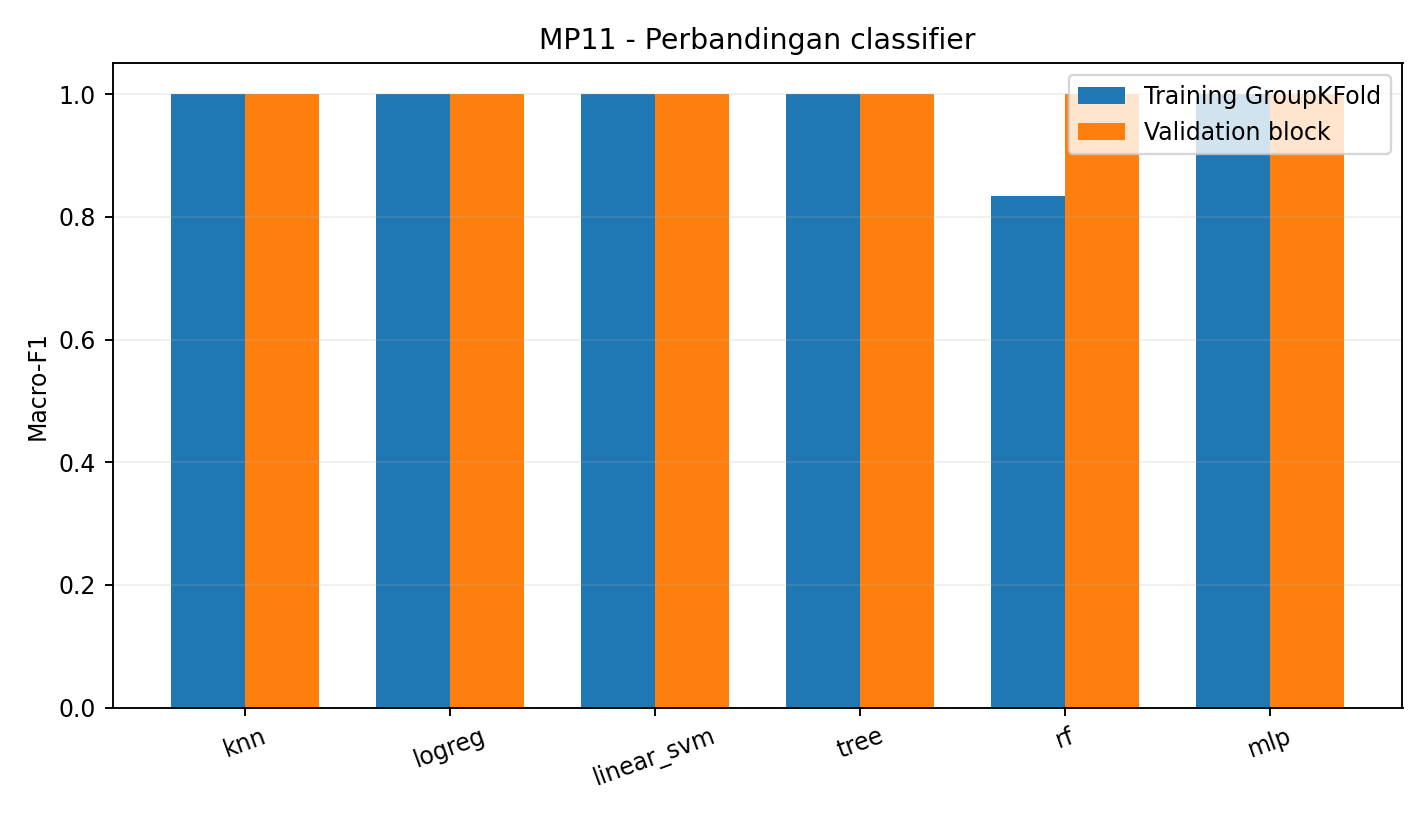

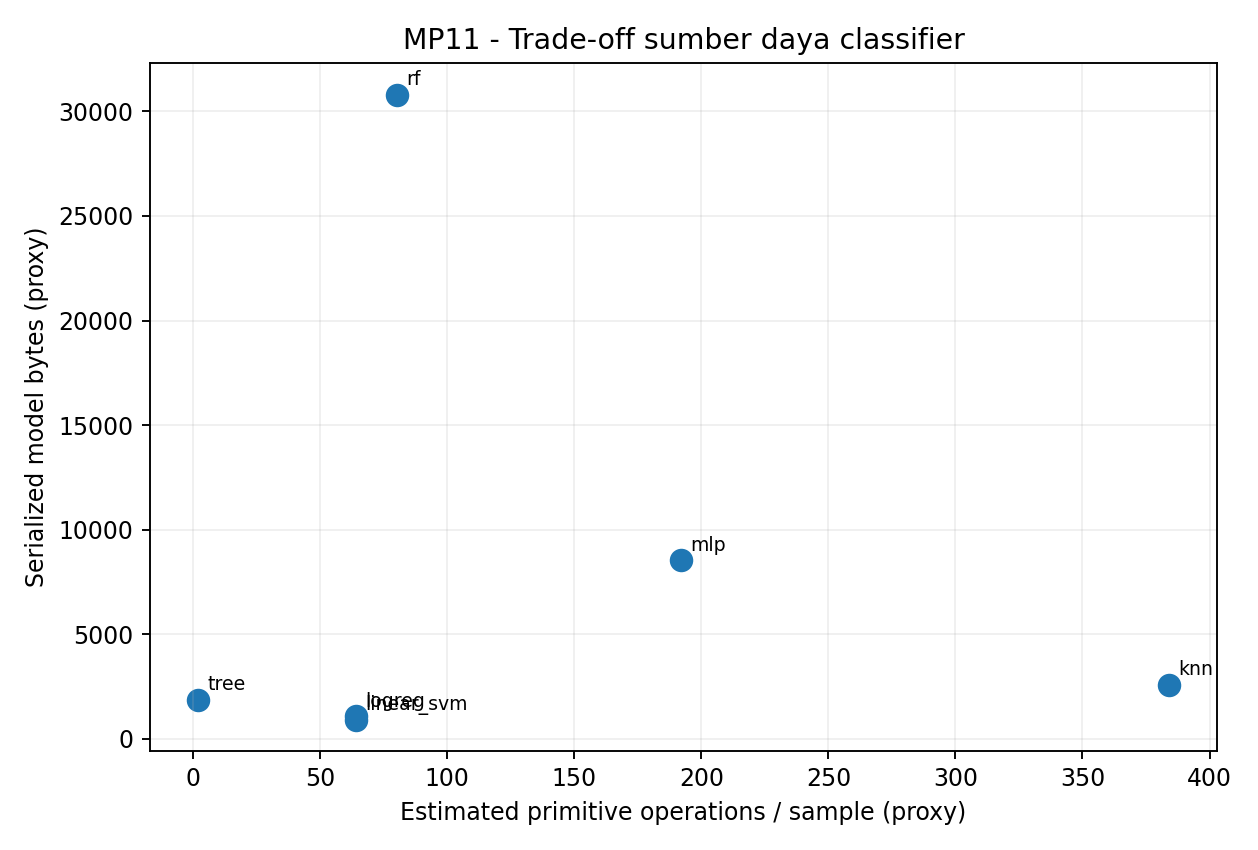

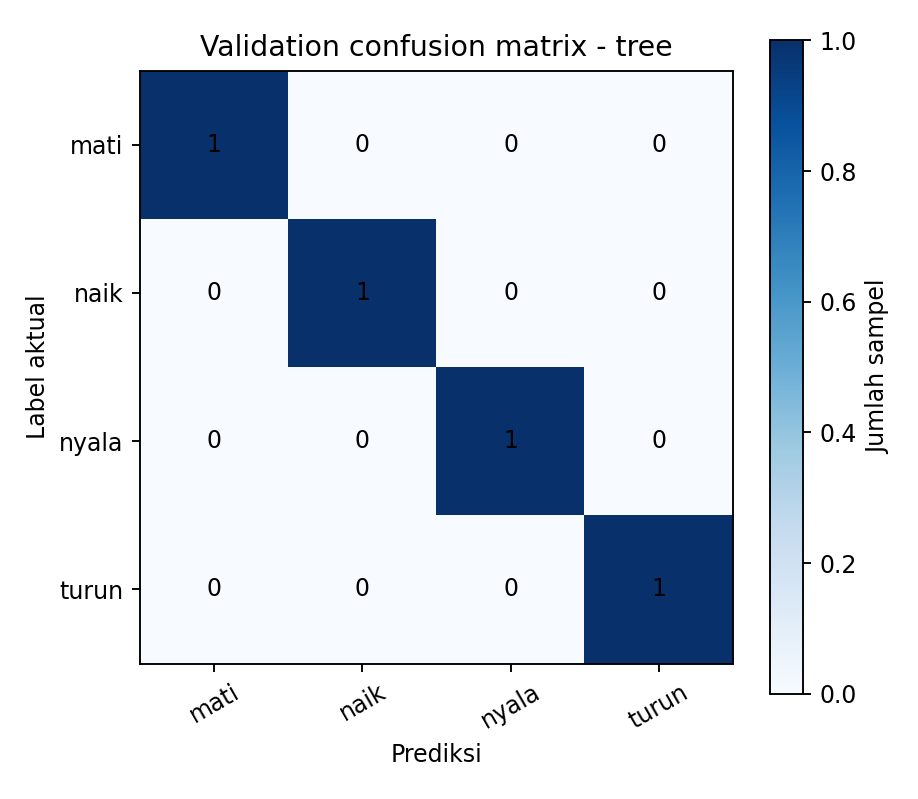

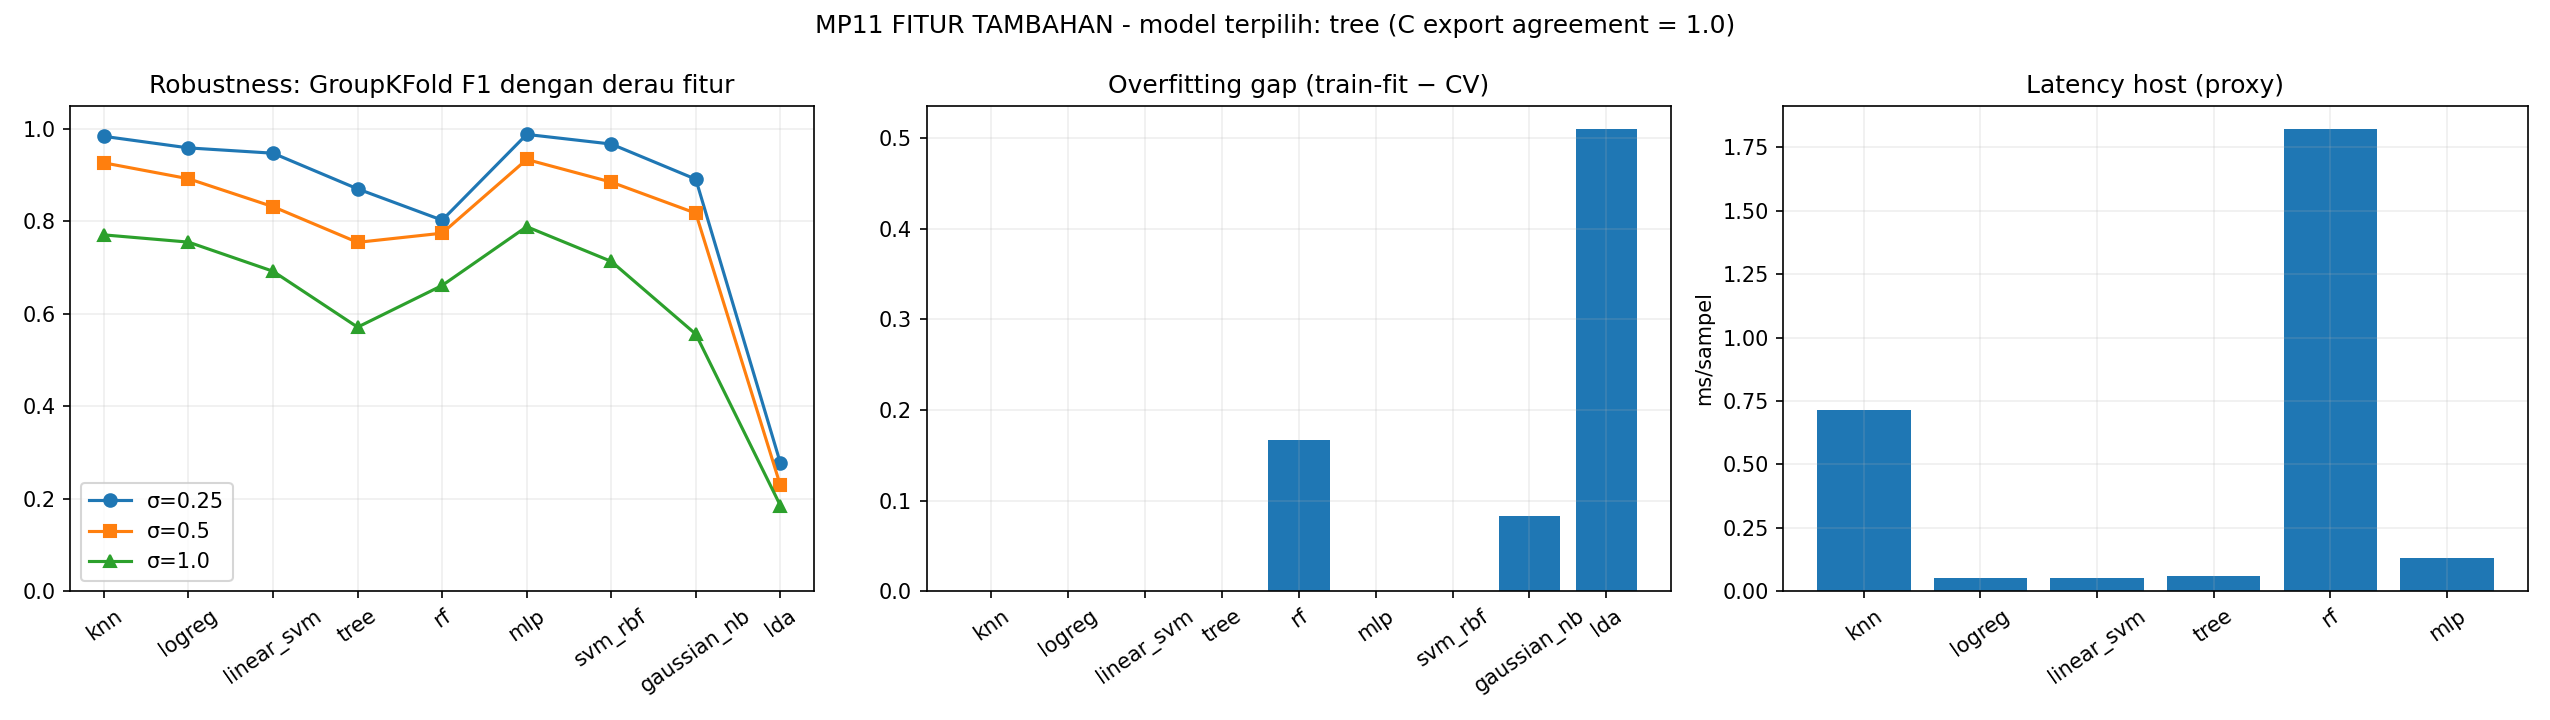

In [16]:
if "__file__" not in globals():
    from IPython.display import Image, display
    for p in ['mp11_classifier_comparison.png', 'mp11_resource_tradeoff.png', 'mp11_validation_confusion_matrix.png', 'mp11_extension_classifier_analysis.png']:
        display(Image(filename=str(OUT_FIG/p), width=760))